# TP Jour 3 — Spark SQL Avancé, Rigueur Statistique & Couche Gold

### Objectifs de la séance
1. Diagnostiquer l'**asymétrie (`SKEWNESS`)** de vos variables quantitatives et justifier l'emploi d'indicateurs robustes (**Médiane `PERCENTILE_APPROX`**, **IQR `P75 - P25`**, **P90**) plutôt que la seule moyenne arithmétique.
2. Écrire des requêtes **Spark SQL avancées** mobilisant des CTE (`WITH ...`) et des **fonctions de fenêtrage** (`DENSE_RANK`, `ROW_NUMBER`, cumul de **Pareto**, variation temporelle **`LAG`**).
3. Construire au moins **2 à 3 tables agrégées métier dans `/lakehouse/gold/`** prêtes à alimenter votre Dashboard Streamlit à faible latence.
4. Éviter le *Small Files Problem* sur HDFS et compacter votre table Silver avec `OPTIMIZE`.

In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("J3_Analytics_SQL_Gold")
    .getOrCreate()
)

# TODO : Enregistrer votre table Silver principale sous forme de vue temporaire SQL `v_silver`
SILVER_MAIN_PATH = "/lakehouse/silver/accidents_enriched"
spark.read.format("delta").load(SILVER_MAIN_PATH).createOrReplaceTempView("v_silver")
print("Lignes disponibles dans v_silver :", spark.sql("SELECT COUNT(*) FROM v_silver").collect()[0][0])

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-f12df19f-f1da-4152-aacf-4329fbf5549d;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found

Lignes disponibles dans v_silver : 2047256


## 1. Analyse d'Asymétrie : Moyenne vs Médiane & Écart Interquartile (IQR)

### Exercice 1.1 — Étudier la distribution de votre métrique quantitative principale
Écrivez une requête Spark SQL sur `v_silver` calculant sur votre variable continue principale :
- `COUNT(*)`, `AVG(...)`, `STDDEV(...)`, `SKEWNESS(...)`
- Les quantiles `P25`, `P50` (médiane), `P75`, `P90`, `P95` via `PERCENTILE_APPROX(col, q)` et `MAX(...)`.

Rédigez ensuite en Markdown **votre interprétation statistique** (écart moyenne/médiane, impact des valeurs extrêmes, choix de l'indicateur retenu pour votre dashboard).

In [2]:
# TODO : Calculer moyenne, écart-type, skewness et quantiles (P25, P50, P75, P90, P95) en Spark SQL
df_dist_summary = spark.sql("""
SELECT
        COUNT(*)                                          AS nb_accidents,
        ROUND(AVG(number_of_casualties), 3)               AS moyenne,
        ROUND(STDDEV(number_of_casualties), 3)            AS ecart_type,
        ROUND(SKEWNESS(number_of_casualties), 3)          AS skewness,
        PERCENTILE_APPROX(number_of_casualties, 0.25)     AS p25,
        PERCENTILE_APPROX(number_of_casualties, 0.50)     AS mediane_p50,
        PERCENTILE_APPROX(number_of_casualties, 0.75)     AS p75,
        PERCENTILE_APPROX(number_of_casualties, 0.75)
          - PERCENTILE_APPROX(number_of_casualties, 0.25) AS iqr,
        PERCENTILE_APPROX(number_of_casualties, 0.90)     AS p90,
        PERCENTILE_APPROX(number_of_casualties, 0.95)     AS p95,
        MAX(number_of_casualties)                         AS max
    FROM v_silver
    WHERE number_of_casualties IS NOT NULL
""")
assert df_dist_summary is not None, "TODO : Écrivez la requête SQL de résumé statistique."
df_dist_summary.show(truncate=False)

[Stage 10:>                                                       (0 + 10) / 11]

+------------+-------+----------+--------+---+-----------+---+---+---+---+---+
|nb_accidents|moyenne|ecart_type|skewness|p25|mediane_p50|p75|iqr|p90|p95|max|
+------------+-------+----------+--------+---+-----------+---+---+---+---+---+
|2047256     |1.346  |0.818     |8.573   |1  |1          |1  |0  |2  |3  |93 |
+------------+-------+----------+--------+---+-----------+---+---+---+---+---+



/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
                                                                                

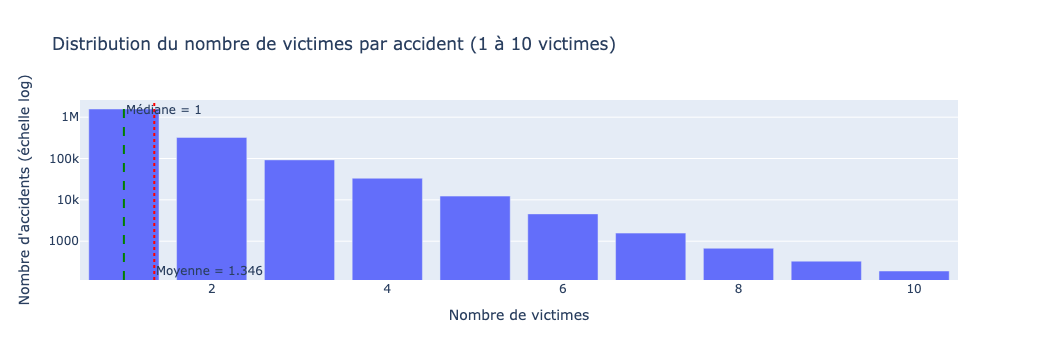

In [3]:
# Graphique 1 — Distribution du nombre de victimes par accident
# Bonne pratique Big Data : on agrège côté Spark (~40 lignes) AVANT toPandas(), jamais les 2 M de lignes
import plotly.express as px

pdf_dist = spark.sql("""
    SELECT number_of_casualties AS victimes, COUNT(*) AS nb_accidents
    FROM v_silver
    WHERE number_of_casualties IS NOT NULL
    GROUP BY number_of_casualties
    ORDER BY victimes
""").toPandas()

stats = df_dist_summary.first()
fig = px.bar(
    pdf_dist[pdf_dist["victimes"] <= 10], x="victimes", y="nb_accidents", log_y=True,
    labels={"victimes": "Nombre de victimes", "nb_accidents": "Nombre d'accidents (échelle log)"},
    title="Distribution du nombre de victimes par accident (1 à 10 victimes)",
)
fig.add_vline(x=stats["mediane_p50"], line_dash="dash", line_color="green",
              annotation_text=f"Médiane = {stats['mediane_p50']}", annotation_position="top right")
fig.add_vline(x=stats["moyenne"], line_dash="dot", line_color="red",
              annotation_text=f"Moyenne = {stats['moyenne']}", annotation_position="bottom right")
fig.show()

**Votre justification statistique *(À compléter)* :**
> La plupart des accidents ne font qu'une seule victime : la médiane, le P25 et le P75 valent tous 1.
Quelques accidents rares font beaucoup de victimes (jusqu'à 93). Ils tirent la moyenne vers le haut (1,35), alors qu'aucun accident réel n'a 1,35 victime. La skewness de 8,57 confirme que les données sont très déséquilibrées.

>Conclusion : la moyenne est trompeuse. Pour le dashboard, on utilise la médiane pour un accident typique, et le P90 / P95 pour suivre les accidents graves.`

---
## 2. Table Gold #1 : Classement Métier & Loi de Pareto (`OVER ORDER BY ...`)

### Exercice 2.1 — Agrégation par segment/catégorie + Courbe cumulée de Pareto
Construisez en Spark SQL une première table Gold agrégée par une dimension métier pertinente de votre dataset incluant :
- Le volume d'observations, le total et les indicateurs robustes (**médiane**, **IQR**).
- Le rang via `DENSE_RANK() OVER (ORDER BY ... DESC)`.
- Le pourcentage cumulé du total (**analyse de Pareto 80/20**) via :
  `SUM(metric_total) OVER (ORDER BY metric_total DESC ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) / SUM(metric_total) OVER ()`.

Sauvegardez-la avec `.coalesce(1)` au format **Delta** dans `/lakehouse/gold/<nom_gold_1>`.

In [4]:
GOLD_PARETO_PATH = "/lakehouse/gold/pareto_districts"

df_gold_1 = spark.sql("""
    WITH stats_district AS (
        -- 1) Une ligne par district : volumes + indicateurs robustes
        SELECT
            local_authority_district                                        AS district,
            COUNT(*)                                                        AS nb_accidents,
            SUM(number_of_casualties)                                       AS total_victimes,
            PERCENTILE_APPROX(number_of_casualties, 0.5)                    AS mediane_victimes,
            PERCENTILE_APPROX(number_of_casualties, 0.75)
              - PERCENTILE_APPROX(number_of_casualties, 0.25)               AS iqr_victimes,
            PERCENTILE_APPROX(number_of_casualties, 0.9)                    AS p90_victimes,
            ROUND(AVG(CASE WHEN number_of_casualties >= 2 THEN 1 ELSE 0 END) * 100, 2)
                                                                            AS pct_accidents_lourds,
            ROUND(AVG(CASE WHEN accident_severity IN ('Serious', 'Fatal') THEN 1 ELSE 0 END) * 100, 2)
                                                                            AS pct_graves_mortels
        FROM v_silver
        WHERE local_authority_district IS NOT NULL
        GROUP BY local_authority_district
    ),
    pareto AS (
        -- 2) Classement + cumul de Pareto
        SELECT
            *,
            DENSE_RANK() OVER (ORDER BY total_victimes DESC)                AS rang,
            SUM(total_victimes) OVER (
                ORDER BY total_victimes DESC, district
                ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
            )                                                               AS victimes_cumulees,
            SUM(total_victimes) OVER ()                                     AS total_general
        FROM stats_district
    )
    -- 3) Pourcentages et repérage des districts qui forment les 80 %
    SELECT
        rang,
        district,
        nb_accidents,
        total_victimes,
        mediane_victimes,
        iqr_victimes,
        p90_victimes,
        pct_accidents_lourds,
        pct_graves_mortels,
        ROUND(total_victimes / total_general * 100, 2)                      AS pct_victimes,
        ROUND(victimes_cumulees / total_general * 100, 2)                   AS pct_cumule,
        (victimes_cumulees - total_victimes) < 0.8 * total_general          AS dans_les_80_pct
    FROM pareto
    ORDER BY rang, district
""")

assert df_gold_1 is not None, "TODO : Écrivez la requête SQL avec fenêtre de Pareto dans `df_gold_1`."

# Sauvegarde Gold : petite table -> 1 seul fichier
(df_gold_1.coalesce(1)
    .write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(GOLD_PARETO_PATH))

df_gold_1.show(15, truncate=False)

# Résumé Pareto
nb_total = df_gold_1.count()
nb_80 = df_gold_1.filter("dans_les_80_pct").count()
print(f"{nb_80} districts sur {nb_total} ({nb_80 / nb_total:.1%}) concentrent 80 % des victimes.")


26/11/18 08:28:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 0

+----+------------------+------------+--------------+----------------+------------+------------+--------------------+------------------+------------+----------+---------------+
|rang|district          |nb_accidents|total_victimes|mediane_victimes|iqr_victimes|p90_victimes|pct_accidents_lourds|pct_graves_mortels|pct_victimes|pct_cumule|dans_les_80_pct|
+----+------------------+------------+--------------+----------------+------------+------------+--------------------+------------------+------------+----------+---------------+
|1   |Birmingham        |39662       |54415         |1               |0           |2           |24.25               |13.27             |1.97        |1.97      |true           |
|2   |Leeds             |27334       |37779         |1               |0           |2           |24.88               |14.48             |1.37        |3.35      |true           |
|3   |Bradford          |18147       |26519         |1               |1           |3           |28.01              

26/11/18 08:28:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


241 districts sur 416 (57.9%) concentrent 80 % des victimes.


26/11/18 08:28:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 0

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


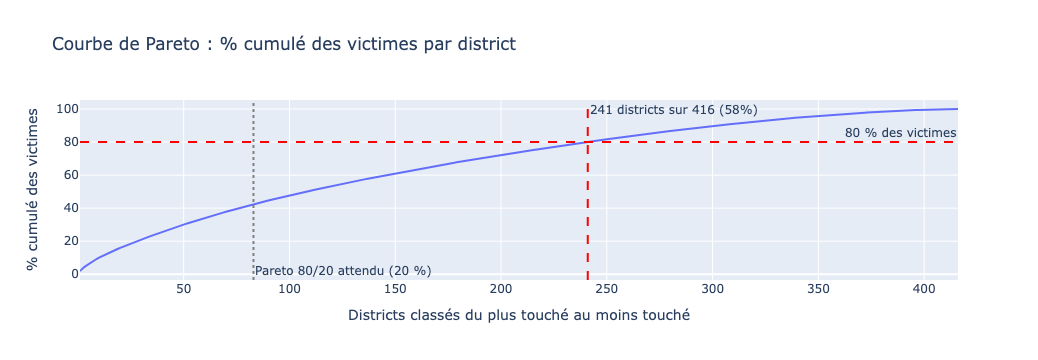

In [5]:
# Graphique 2 — Courbe de Pareto (lue depuis la table Gold : 416 lignes, toPandas() sans risque)
import plotly.express as px

pdf_pareto = (spark.read.format("delta").load(GOLD_PARETO_PATH)
              .select("rang", "district", "total_victimes", "pct_cumule", "dans_les_80_pct")
              .orderBy("pct_cumule")
              .toPandas())
pdf_pareto["position"] = range(1, len(pdf_pareto) + 1)
nb_80 = int(pdf_pareto["dans_les_80_pct"].sum())
nb_total = len(pdf_pareto)

fig = px.line(
    pdf_pareto, x="position", y="pct_cumule", hover_name="district",
    hover_data={"total_victimes": True, "position": False},
    labels={"position": "Districts classés du plus touché au moins touché",
            "pct_cumule": "% cumulé des victimes"},
    title="Courbe de Pareto : % cumulé des victimes par district",
)
fig.add_hline(y=80, line_dash="dash", line_color="red", annotation_text="80 % des victimes")
fig.add_vline(x=nb_80, line_dash="dash", line_color="red",
              annotation_text=f"{nb_80} districts sur {nb_total} ({nb_80 / nb_total:.0%})")
# Référence : une vraie loi 80/20 atteindrait 80 % dès 20 % des districts
fig.add_vline(x=round(0.2 * nb_total), line_dash="dot", line_color="gray",
              annotation_text="Pareto 80/20 attendu (20 %)", annotation_position="bottom right")
fig.show()

>La loi de Pareto ne s'applique pas ici, La loi de Pareto prédit qu'environ 20 % des districts concentreraient 80 % des victimes. Ici, il en faut 58 %, presque trois fois plus.


Pareto « classique » : 20 % des districts → 80 % des victimes   (concentré)
Nos données          : 58 % des districts → 80 % des victimes   (réparti)
Répartition égale    : 80 % des districts → 80 % des victimes   (parfaitement égal)

Nos données sont plus proches d'une répartition égale que d'une concentration. Les victimes sont réparties sur une grande partie du territoire, et non concentrées dans quelques « points noirs ».

## 3. Table Gold #2 : Dynamique Temporelle & Croissance avec `LAG()`

### Exercice 3.1 — Série temporelle et taux d'évolution période-sur-période
Agrégez votre table `v_silver` selon son axe temporel (jour, semaine, mois ou année selon votre sujet) et utilisez la fonction de fenêtrage **`LAG(metric, 1) OVER (ORDER BY periode)`** (ou une moyenne glissante `AVG(...) OVER (ORDER BY periode ROWS BETWEEN ... PRECEDING AND CURRENT ROW)`) pour mesurer la dynamique d'évolution.

Sauvegardez le résultat dans `/lakehouse/gold/<nom_gold_2>`.

In [6]:
GOLD_TIME_PATH = "/lakehouse/gold/evolution_mensuelle"

df_gold_2 = spark.sql("""
    WITH mensuel AS (
        -- 1) Une ligne par mois
        SELECT
            DATE_TRUNC('MONTH', accident_date)                       AS mois,
            COUNT(*)                                                 AS nb_accidents,
            SUM(number_of_casualties)                                AS total_victimes,
            SUM(CASE WHEN accident_severity IN ('Serious', 'Fatal') THEN 1 ELSE 0 END)
                                                                     AS nb_graves_mortels
        FROM v_silver
        WHERE accident_date IS NOT NULL
        GROUP BY DATE_TRUNC('MONTH', accident_date)
    ),
    avec_lag AS (
        -- 2) Valeurs du mois précédent et du même mois l'an dernier
        SELECT
            *,
            LAG(nb_accidents, 1)  OVER (ORDER BY mois)               AS nb_accidents_mois_prec,
            LAG(nb_accidents, 12) OVER (ORDER BY mois)               AS nb_accidents_annee_prec,
            AVG(nb_accidents)     OVER (ORDER BY mois
                                        ROWS BETWEEN 11 PRECEDING AND CURRENT ROW)
                                                                     AS moy_glissante_12m
        FROM mensuel
    )
    -- 3) Taux d'évolution
    SELECT
        CAST(mois AS DATE)                                           AS mois,
        nb_accidents,
        total_victimes,
        nb_graves_mortels,
        ROUND(nb_graves_mortels / nb_accidents * 100, 2)             AS pct_graves_mortels,
        nb_accidents_mois_prec,
        ROUND((nb_accidents - nb_accidents_mois_prec) / nb_accidents_mois_prec * 100, 2)
                                                                     AS evol_vs_mois_prec_pct,
        nb_accidents_annee_prec,
        ROUND((nb_accidents - nb_accidents_annee_prec) / nb_accidents_annee_prec * 100, 2)
                                                                     AS evol_vs_annee_prec_pct,
        ROUND(moy_glissante_12m, 0)                                  AS moy_glissante_12m
    FROM avec_lag
    ORDER BY mois
""")

assert df_gold_2 is not None, "TODO : Écrivez la requête SQL temporelle avec LAG() dans `df_gold_2`."

(df_gold_2.coalesce(1)
    .write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(GOLD_TIME_PATH))

df_gold_2.show(20, truncate=False)


26/11/18 08:28:48 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:48 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 0

+----------+------------+--------------+-----------------+------------------+----------------------+---------------------+-----------------------+----------------------+-----------------+
|mois      |nb_accidents|total_victimes|nb_graves_mortels|pct_graves_mortels|nb_accidents_mois_prec|evol_vs_mois_prec_pct|nb_accidents_annee_prec|evol_vs_annee_prec_pct|moy_glissante_12m|
+----------+------------+--------------+-----------------+------------------+----------------------+---------------------+-----------------------+----------------------+-----------------+
|2005-01-01|16278       |22055         |2143             |13.17             |NULL                  |NULL                 |NULL                   |NULL                  |16278.0          |
|2005-02-01|14521       |19617         |1917             |13.2              |16278                 |-10.79               |NULL                   |NULL                  |15400.0          |
|2005-03-01|14977       |20365         |2052             |13

26/11/18 08:28:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 08:28:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


In [7]:
from pyspark.sql import functions as F

g2 = spark.read.format("delta").load(GOLD_TIME_PATH)

# 1) Vérifier la période couverte (et si le dernier mois est complet)
print("=== 1) Période couverte ===")
g2.agg(F.min("mois").alias("premier_mois"), F.max("mois").alias("dernier_mois"),
       F.count("*").alias("nb_mois")).show()
print("Derniers mois (repérer une année incomplète) :")
g2.orderBy(F.desc("mois")).select("mois", "nb_accidents").show(6)

# 2) Tendance générale : résumé par année
print("=== 2) Tendance par année ===")
(g2.groupBy(F.year("mois").alias("annee"))
   .agg(F.count("*").alias("nb_mois"),
        F.sum("nb_accidents").alias("nb_accidents"),
        F.sum("total_victimes").alias("total_victimes"),
        F.round(F.sum("nb_graves_mortels") / F.sum("nb_accidents") * 100, 2).alias("pct_graves_mortels"))
   .orderBy("annee")
   .show(20))

# 3) Saisonnalité : moyenne d'accidents par mois calendaire (tous les ans confondus)
print("=== 3) Saisonnalité (moyenne par mois de l'année) ===")
(g2.groupBy(F.month("mois").alias("mois_calendaire"))
   .agg(F.round(F.avg("nb_accidents"), 0).alias("moy_accidents"),
        F.round(F.avg("pct_graves_mortels"), 2).alias("moy_pct_graves"))
   .orderBy(F.desc("moy_accidents"))
   .show(12))

# 4) Évolution globale de la moyenne glissante (début vs fin)
first = g2.filter(F.col("nb_accidents_annee_prec").isNotNull()).orderBy("mois").first()
last = g2.orderBy(F.desc("mois")).first()
evol = (last["moy_glissante_12m"] - first["moy_glissante_12m"]) / first["moy_glissante_12m"] * 100
print("=== 4) Tendance lissée (moyenne glissante 12 mois) ===")
print(f"{first['mois']} : {first['moy_glissante_12m']:,.0f} accidents/mois")
print(f"{last['mois']} : {last['moy_glissante_12m']:,.0f} accidents/mois")
print(f"Évolution : {evol:+.1f} %")


=== 1) Période couverte ===
+------------+------------+-------+
|premier_mois|dernier_mois|nb_mois|
+------------+------------+-------+
|  2005-01-01|  2017-12-01|    156|
+------------+------------+-------+

Derniers mois (repérer une année incomplète) :
+----------+------------+
|      mois|nb_accidents|
+----------+------------+
|2017-12-01|       10470|
|2017-11-01|       11958|
|2017-10-01|       11194|
|2017-09-01|       11091|
|2017-08-01|       10301|
|2017-07-01|       11450|
+----------+------------+
only showing top 6 rows
=== 2) Tendance par année ===
+-----+-------+------------+--------------+------------------+
|annee|nb_mois|nb_accidents|total_victimes|pct_graves_mortels|
+-----+-------+------------+--------------+------------------+
| 2005|     12|      198735|        271017|             14.06|
| 2006|     12|      189161|        258404|             14.73|
| 2007|     12|      182115|        247780|             14.85|
| 2008|     12|      170591|        230905|         

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


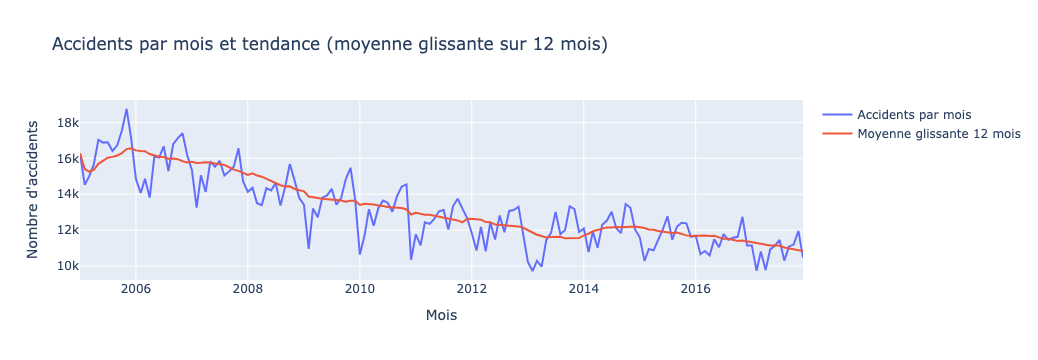

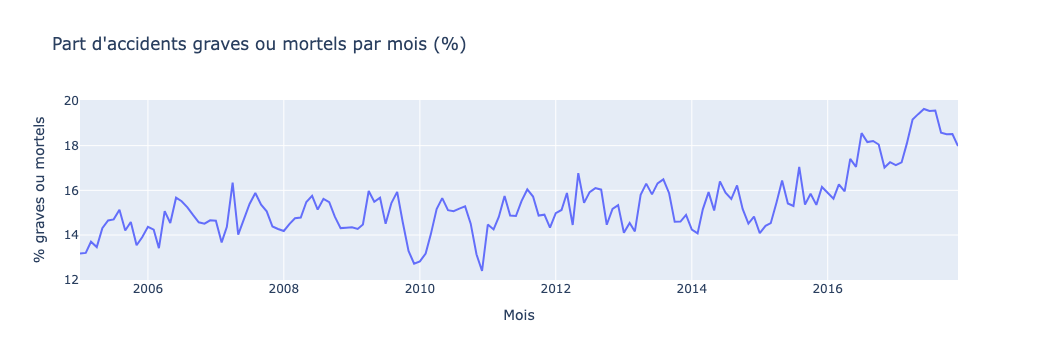

In [8]:
# Graphique 3 — Évolution temporelle (lue depuis la table Gold : 156 mois)
import plotly.express as px

pdf_time = (spark.read.format("delta").load(GOLD_TIME_PATH)
            .select("mois", "nb_accidents", "moy_glissante_12m", "pct_graves_mortels")
            .orderBy("mois")
            .toPandas())

# 3a) Nombre d'accidents par mois + tendance lissée
fig = px.line(
    pdf_time.rename(columns={"nb_accidents": "Accidents par mois",
                             "moy_glissante_12m": "Moyenne glissante 12 mois"}),
    x="mois", y=["Accidents par mois", "Moyenne glissante 12 mois"],
    labels={"mois": "Mois", "value": "Nombre d'accidents", "variable": ""},
    title="Accidents par mois et tendance (moyenne glissante sur 12 mois)",
)
fig.show()

# 3b) Part d'accidents graves ou mortels
fig = px.line(
    pdf_time, x="mois", y="pct_graves_mortels",
    labels={"mois": "Mois", "pct_graves_mortels": "% graves ou mortels"},
    title="Part d'accidents graves ou mortels par mois (%)",
)
fig.show()

>Interprétation de l'évolution temporelle
Les accidents baissent : de 198 735 en 2005 à 129 982 en 2017, soit un tiers de moins (−35 %).
Mais ils sont plus graves : la part d'accidents graves ou mortels passe de 14 % à 19 %. Ce sont surtout les petits accidents qui ont diminué.
Les saisons comptent : il y a plus d'accidents en octobre et novembre (nuits plus longues, pluie), et des accidents plus graves en été.

## 4. Table Gold #3 (Axe complémentaire libre) & Compaction `OPTIMIZE`

### Exercice 4.1 — Produire un 3e axe d'analyse (`ROW_NUMBER() OVER (PARTITION BY ...)`) et compacter Silver
1. Créez une 3e table Gold répondant à une question spécifique de votre problématique (ex. top sous-catégorie par région/groupe via `ROW_NUMBER() OVER (PARTITION BY groupe ORDER BY ... DESC) = 1`).
2. Exécutez `OPTIMIZE delta.'{SILVER_MAIN_PATH}'` et expliquez pourquoi la multiplication de micro-fichiers pénalise le NameNode HDFS.

In [9]:
GOLD_FACTEURS_PATH = "/lakehouse/gold/facteurs_gravite"
MIN_ACCIDENTS = 1000   # on ignore les modalités trop rares (taux peu fiables)

df_gold_3 = spark.sql(f"""
    WITH long_format AS (
        -- 1) On « empile » plusieurs facteurs dans 2 colonnes : facteur / modalite
        SELECT
            STACK(8,
                'Luminosité',       CAST(light_conditions        AS STRING),
                'Météo',            CAST(weather_conditions      AS STRING),
                'Type de route',    CAST(road_type               AS STRING),
                'État de la route', CAST(road_surface_conditions AS STRING),
                'Limite de vitesse',CAST(speed_limit             AS STRING),
                'Zone',             CAST(urban_or_rural_area     AS STRING),
                'Week-end',         CAST(is_weekend              AS STRING),
                'Jeune conducteur', CAST(has_young_driver        AS STRING)
            ) AS (facteur, modalite),
            CASE WHEN accident_severity IN ('Serious', 'Fatal') THEN 1 ELSE 0 END AS est_grave,
            CASE WHEN accident_severity = 'Fatal' THEN 1 ELSE 0 END               AS est_mortel
        FROM v_silver
    ),
    stats AS (
        -- 2) Taux de gravité par facteur et modalité
        SELECT
            facteur,
            modalite,
            COUNT(*)                                 AS nb_accidents,
            ROUND(AVG(est_grave) * 100, 2)           AS pct_graves_mortels,
            ROUND(AVG(est_mortel) * 100, 2)          AS pct_mortels
        FROM long_format
        WHERE modalite IS NOT NULL
        GROUP BY facteur, modalite
        HAVING COUNT(*) >= {MIN_ACCIDENTS}
    ),
    taux_global AS (
        SELECT AVG(CASE WHEN accident_severity IN ('Serious', 'Fatal') THEN 1 ELSE 0 END) * 100 AS pct_global
        FROM v_silver
    )
    -- 3) Classement À L'INTÉRIEUR de chaque facteur + comparaison au taux global
    SELECT
        s.facteur,
        ROW_NUMBER() OVER (PARTITION BY s.facteur ORDER BY s.pct_graves_mortels DESC) AS rang_dans_facteur,
        s.modalite,
        s.nb_accidents,
        s.pct_graves_mortels,
        s.pct_mortels,
        ROUND(s.pct_graves_mortels / t.pct_global, 2)                                 AS risque_relatif
    FROM stats s
    CROSS JOIN taux_global t
    ORDER BY s.facteur, rang_dans_facteur
""")

(df_gold_3.coalesce(1)
    .write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(GOLD_FACTEURS_PATH))

# Vue 1 : la modalité la PLUS aggravante de chaque facteur (rang = 1)
print("=== Modalité la plus aggravante par facteur ===")
(df_gold_3.filter("rang_dans_facteur = 1")
    .orderBy(F.desc("risque_relatif"))
    .show(truncate=False))

# Vue 2 : le détail complet
print("=== Détail complet ===")
df_gold_3.show(100, truncate=False)

# ---------- OPTIMIZE : compaction de la table Silver ----------
print("Nombre de fichiers AVANT :",
      spark.sql(f"DESCRIBE DETAIL delta.`{SILVER_MAIN_PATH}`").first()["numFiles"])

spark.sql(f"OPTIMIZE delta.`{SILVER_MAIN_PATH}`").show(truncate=False)

print("Nombre de fichiers APRÈS :",
      spark.sql(f"DESCRIBE DETAIL delta.`{SILVER_MAIN_PATH}`").first()["numFiles"])


=== Modalité la plus aggravante par facteur ===
+-----------------+-----------------+----------------------+------------+------------------+-----------+--------------+
|facteur          |rang_dans_facteur|modalite              |nb_accidents|pct_graves_mortels|pct_mortels|risque_relatif|
+-----------------+-----------------+----------------------+------------+------------------+-----------+--------------+
|Luminosité       |1                |Darkness - no lighting|112644      |24.27             |4.39       |1.59          |
|Limite de vitesse|1                |60                    |317469      |22.46             |3.15       |1.47          |
|Zone             |1                |Rural                 |724757      |18.85             |2.35       |1.23          |
|Week-end         |1                |true                  |498479      |17.66             |1.75       |1.16          |
|Météo            |1                |Fine + high winds     |25816       |17.07             |1.86       |1.12    

+--------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|path                                                    |metrics                                                                                                                                                                                                 |
+--------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|hdfs://namenode:9000/lakehouse/silver/accidents_enriched|{1, 11, {108331984, 108331984, 1.08331984E8, 1, 108331984}, {3614808, 10844461, 9908637.090909092, 11, 108995008}, 1, NULL, NULL, 1, 1, 11, 0, false, 0, 0, 179499

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


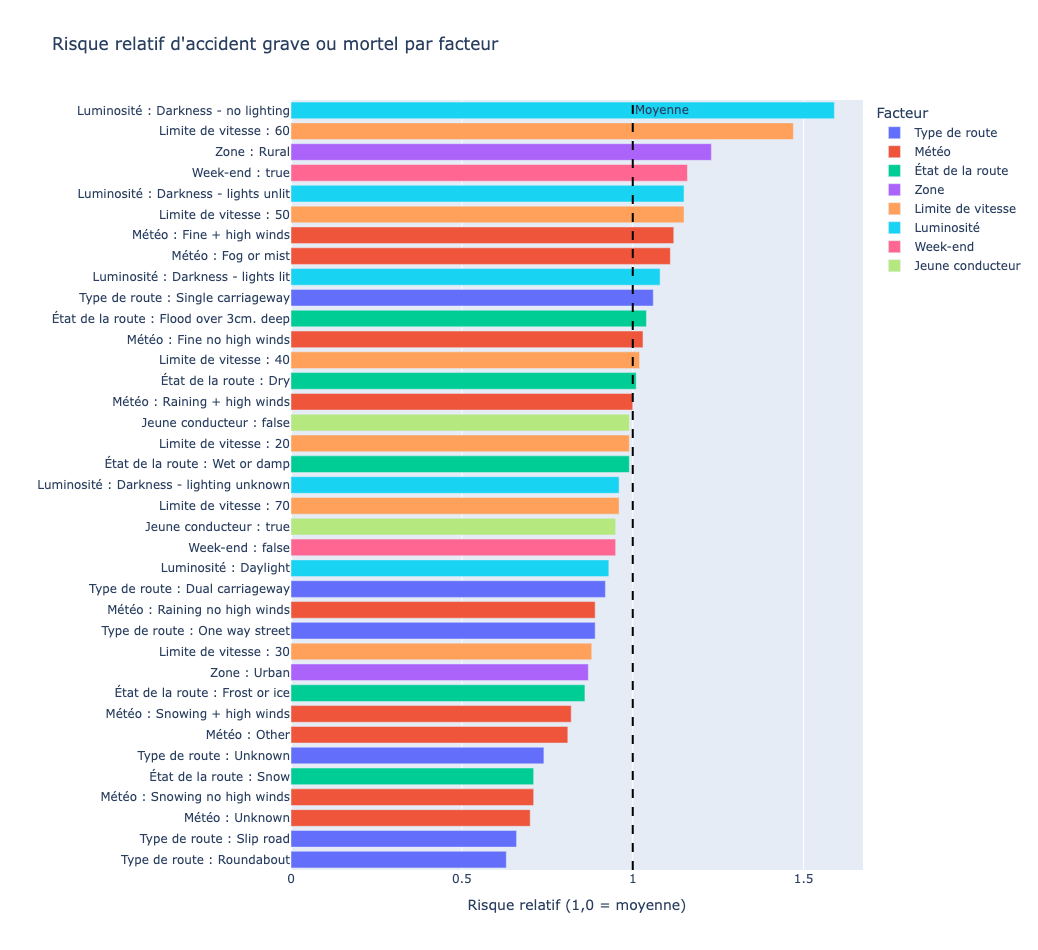

In [10]:
# Graphique 4 — Risque relatif d'accident grave par facteur (lu depuis la table Gold : 37 lignes)
import plotly.express as px

pdf_fact = (spark.read.format("delta").load(GOLD_FACTEURS_PATH)
            .toPandas()
            .sort_values("risque_relatif"))
pdf_fact["libelle"] = pdf_fact["facteur"] + " : " + pdf_fact["modalite"]

fig = px.bar(
    pdf_fact, x="risque_relatif", y="libelle", color="facteur", orientation="h",
    hover_data=["nb_accidents", "pct_graves_mortels", "pct_mortels"],
    labels={"risque_relatif": "Risque relatif (1,0 = moyenne)", "libelle": "", "facteur": "Facteur"},
    title="Risque relatif d'accident grave ou mortel par facteur",
    height=950,
)
fig.update_yaxes(categoryorder="total ascending")   # tri global, toutes couleurs confondues
fig.add_vline(x=1, line_dash="dash", line_color="black", annotation_text="Moyenne")
fig.show()

#### Quels facteurs aggravent les accidents ?
En moyenne, 15 % des accidents sont graves ou mortels.

#### Les facteurs les plus aggravants :

- La nuit sans éclairage : 24 % d'accidents graves, et 4 fois plus d'accidents mortels qu'en plein jour.
- Les routes limitées à 60 mph : 22 % d'accidents graves. On y roule vite, sur des routes simples.
- La campagne : 19 % d'accidents graves, contre 13 % en ville.
- Le week-end : un peu plus grave qu'en semaine.
- Surprise : la pluie, la neige et le verglas rendent les accidents moins graves, probablement parce que les conducteurs ralentissent. Les ronds-points sont les endroits les moins graves, et les jeunes conducteurs n'ont pas d'accidents plus graves que les autres.

#### Conclusion : 
ce qui rend un accident grave, c'est surtout la vitesse et le manque de visibilité (routes de campagne rapides, la nuit, sans éclairage), et non la mauvaise météo.

#### Limite : 
ces facteurs sont liés entre eux (une route de campagne est souvent rapide et non éclairée). Ce sont des corrélations, pas des causes prouvées.

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Nombre d'accidents par case (fiabilité) :
vitesse                    20      30      40     50      60      70
luminosite                                                          
Daylight                28353  959071  122549  50260  232742  103097
Darkness - lights lit    9092  313264   35384  11403   14412   20573
Darkness - no lighting      0   11001    7289   6552   66749   20817


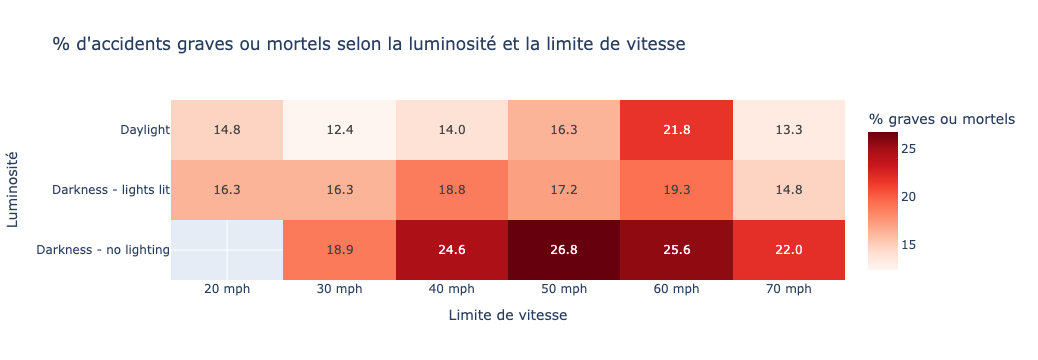


Écart (nuit sans éclairage − jour), en points de %, à vitesse égale :
vitesse
20     NaN
30     6.5
40    10.6
50    10.5
60     3.8
70     8.7


In [11]:
# Graphique 5 — Heatmap croisée : Luminosité × Limite de vitesse → % d'accidents graves ou mortels
# Question : à vitesse ÉGALE (même colonne), la nuit sans éclairage reste-t-elle plus grave que le jour ?
# Bonne pratique : agrégation côté Spark (~30 cases) AVANT toPandas()
import plotly.express as px

MIN_CASE = 500   # on masque les cases trop petites (taux peu fiables)

pdf_cross = spark.sql(f"""
    SELECT
        light_conditions                                                         AS luminosite,
        speed_limit                                                              AS vitesse,
        COUNT(*)                                                                 AS nb_accidents,
        ROUND(AVG(CASE WHEN accident_severity IN ('Serious', 'Fatal') THEN 1 ELSE 0 END) * 100, 1)
                                                                                 AS pct_graves_mortels
    FROM v_silver
    WHERE light_conditions IN ('Daylight', 'Darkness - lights lit', 'Darkness - no lighting')
      AND speed_limit IN (20, 30, 40, 50, 60, 70)
    GROUP BY light_conditions, speed_limit
    HAVING COUNT(*) >= {MIN_CASE}
""").toPandas()

# Tableau croisé : lignes = luminosité, colonnes = vitesse
ordre_lum = ["Daylight", "Darkness - lights lit", "Darkness - no lighting"]
pivot_pct = (pdf_cross.pivot(index="luminosite", columns="vitesse", values="pct_graves_mortels")
             .reindex(ordre_lum).sort_index(axis=1))
pivot_nb = (pdf_cross.pivot(index="luminosite", columns="vitesse", values="nb_accidents")
            .reindex(ordre_lum).sort_index(axis=1))

print("Nombre d'accidents par case (fiabilité) :")
print(pivot_nb.fillna(0).astype(int))

fig = px.imshow(
    pivot_pct,
    x=[f"{v} mph" for v in pivot_pct.columns], y=pivot_pct.index,
    text_auto=".1f", color_continuous_scale="Reds", aspect="auto",
    labels={"x": "Limite de vitesse", "y": "Luminosité", "color": "% graves ou mortels"},
    title="% d'accidents graves ou mortels selon la luminosité et la limite de vitesse",
)
fig.show()

# Lecture rapide : écart nuit sans éclairage vs jour, colonne par colonne
ecart = (pivot_pct.loc["Darkness - no lighting"] - pivot_pct.loc["Daylight"]).round(1)
print("\nÉcart (nuit sans éclairage − jour), en points de %, à vitesse égale :")
print(ecart.to_string())


#### Interprétation
> **La nuit sans éclairage aggrave les accidents, même à vitesse égale.** Dans chaque colonne, la ligne *Darkness - no lighting* est plus grave que *Daylight* : de **+4 points** (60 mph) à **+11 points** (40 et 50 mph). Par exemple, à 40 mph : 14 % d'accidents graves le jour, contre 25 % la nuit sans éclairage, presque **deux fois plus**.

> **L'éclairage public protège en partie.** La nuit avec éclairage (*lights lit*) se place presque toujours entre le jour et la nuit sans éclairage.

> **La vitesse compte aussi.** Même en plein jour, les routes à 60 mph sont les plus graves (21,8 %). Les routes à 70 mph (autoroutes, voies séparées) restent peu graves de jour (13,3 %).

> **Conclusion :** les deux facteurs jouent **chacun de leur côté**, et ils s'additionnent : le pire cas est une route rapide de campagne, la nuit, sans éclairage. La limite de l'analyse précédente est levée en partie : l'effet de la nuit n'est pas seulement un effet de la vitesse.

> **Limites :** la case 20 mph de nuit sans éclairage est vide (aucun accident). D'autres facteurs restent possibles la nuit (fatigue, alcool, secours plus lents). Il s'agit toujours d'une corrélation, pas d'une cause prouvée.